# Más neuronas.

Como vimos en el primer ejemplo. La función $f(x)=\sqrt{x}$ es más complicada de ajustar por su comportamiento. Entonces más tiempo no garantizará mejores resultados. Entonces podemos intentar aumentar el número de neuronas. Entonces nuestro modelo tendría esta forma 

$$
\mathfrak{m}(x,\Theta) = \sum_{n=1}^N c^n\sigma(w^nx+b^n),\Theta = \{(c^n,w^n,b^n)\}_{n=1}^N.
$$

## Transformación.

Retomando la forma de Red tendriamos un vector 
$$
\left[\begin{array}{c}
c^{1}\sigma\left(w^{1}x+b^{1}\right)\\
\vdots\\
c^{N}\sigma\left(w^{N}x+b^{N}\right)
\end{array}\right]
$$

Replicando el comportamiento de Python podemos ver esto como 
$$
\mathbf{c}\sigma\left(x\mathbf{w}+\mathbf{b}\right).\text{sum}()
$$
donde $\mathbf{w},\mathbf{c},\mathbf{b}$ son vectores. 


In [73]:
import numpy as np
from neuralnetworks.nn import descent_gradent, verif_model

def sigmoid(x):
    return (1 + np.exp(-x)) ** -1


NEURONS = 5
x_0 = 0.4
W = np.ones(NEURONS)
B = 2 * np.ones(NEURONS)
v = x_0 * W + B
C = list(range(NEURONS))
Sv = sigmoid(v)
Sv
print(C * Sv)

Q = np.zeros((3, NEURONS))
Q[0, :] = C
Q[1, :] = W
Q[2, :] = B



def Nmodel(Q, x, act = sigmoid, neurons = NEURONS):
    C = Q[:NEURONS]
    W = Q[NEURONS : 2*NEURONS]
    B = Q[2*NEURONS:]
    v = W * x + B
    Sv = sigmoid(v)
    CSv = C * Sv
    return CSv.sum()


def Nerror(ydata, xdata, func, pars):
    M = len(xdata)
    pred = np.array([func(pars, x) for x in xdata])
    ell = (ydata - pred) ** 2
    return ell.mean()


train_x = np.linspace(0, 10, 20)
train_y = np.sqrt(train_x)

Q0 = Q.flatten()

def Nlearn(theta):
    return Nerror(train_y, train_x, Nmodel, theta)



pars_0 = descent_gradent(Nlearn, Q0, 0.01, stop=10_000)
pars_0

C0 = pars[:NEURONS]
W0 = pars[NEURONS : 2*NEURONS]
B0 = pars[2*NEURONS:]
print(C0,W0,B0)


[0.         0.9168273  1.83365461 2.75048191 3.66730921]
Error: 0.20160498174450603
Error: 0.20111997666364237
Error: 0.20063541290706696
Error: 0.20015129385306163
Error: 0.19966762287332104
Error: 0.19918440333270676
Error: 0.19870163858918127
Error: 0.19821933199363714
Error: 0.197737486889742
Error: 0.19725610661377563
Error: 0.19677519449452424
Error: 0.19629475385305956
Error: 0.1958147880027487
Error: 0.19533530024892204
Error: 0.1948562938888891
Error: 0.19437777221166413
Error: 0.19389973849796055
Error: 0.19342219601993427
Error: 0.1929451480411346
Error: 0.19246859781633044
Error: 0.19199254859135173
Error: 0.19151700360295593
Error: 0.19104196607878396
Error: 0.19056743923713151
Error: 0.19009342628681974
Error: 0.18961993042713549
Error: 0.18914695484759558
Error: 0.1886745027279713
Error: 0.18820257723794637
Error: 0.18773118153719642
Error: 0.18726031877519445
Error: 0.18678999209103703
Error: 0.18632020461333895
Error: 0.1858509594601444
Error: 0.1853822597388043
Error:

0.009998681885260707


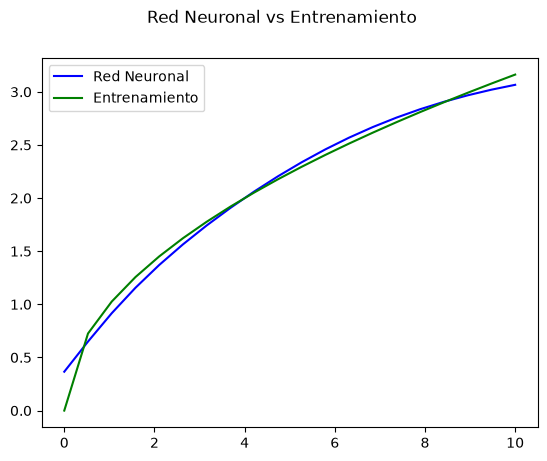

In [74]:
def fitmodel(x):
    return Nmodel(pars_0, x)

print(Nlearn(pars_0))
verif_model(train_y, train_x, fitmodel, pars_0, Nlearn)